In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [16]:
from pathlib import Path

data_path = Path("../data/traffic_dataset.csv")
traffic = pd.read_csv(data_path)

traffic.head()

,reading_id,road_id,sensor_id,timestamp,vehicle_count,avg_speed,density,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12
0,1.0,R001,S001,20-08-2026 00:00,50.0,46.26,0.33,NaN,NaN,NaN,NaN,NaN,NaN
1,2.0,R002,S002,20-08-2026 00:00,45.0,43.33,0.30,NaN,NaN,NaN,NaN,NaN,NaN
2,3.0,R003,S003,20-08-2026 00:00,27.0,51.87,0.18,NaN,NaN,NaN,NaN,NaN,NaN
3,4.0,R004,S004,20-08-2026 00:00,16.0,58.63,0.11,NaN,NaN,NaN,NaN,NaN,NaN
4,5.0,R005,S005,20-08-2026 00:00,49.0,48.24,0.33,NaN,NaN,NaN,NaN,NaN,NaN


In [17]:
print("Rows and Columns:", traffic.shape)
print("\nColumn Names:")
print(traffic.columns)

traffic.info()

Rows and Columns: (841, 13)

Column Names:
Index(['reading_id', 'road_id', 'sensor_id', 'timestamp', 'vehicle_count',
       'avg_speed', 'density', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9',
       'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 841 entries, 0 to 840
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   reading_id     840 non-null    float64
 1   road_id        841 non-null    object 
 2   sensor_id      840 non-null    object 
 3   timestamp      840 non-null    object 
 4   vehicle_count  839 non-null    float64
 5   avg_speed      839 non-null    float64
 6   density        839 non-null    float64
 7   Unnamed: 7     1 non-null      object 
 8   Unnamed: 8     1 non-null      object 
 9   Unnamed: 9     1 non-null      object 
 10  Unnamed: 10    1 non-null      float64
 11  Unnamed: 11    1 non-null      float64
 12  Unnamed:

In [18]:
traffic.describe()

,reading_id,vehicle_count,avg_speed,density,Unnamed: 10,Unnamed: 11,Unnamed: 12
count,840.000000,839.00000,839.000000,839.000000,1.0,1.00,1.00
mean,419.966667,65.38975,42.595006,0.436427,48.0,46.41,0.32
std,242.944225,38.29931,10.557788,0.255065,NaN,NaN,NaN
min,1.000000,10.00000,17.620000,0.070000,48.0,46.41,0.32
25%,209.750000,33.00000,34.995000,0.220000,48.0,46.41,0.32
50%,419.500000,57.00000,44.510000,0.380000,48.0,46.41,0.32
75%,630.250000,91.00000,51.235000,0.610000,48.0,46.41,0.32
max,840.000000,150.00000,60.840000,1.000000,48.0,46.41,0.32


In [19]:
print("Missing Values:")
print(traffic.isnull().sum())

print("\nDuplicate Records:", traffic.duplicated().sum())

Missing Values:
reading_id         1
road_id            0
sensor_id          1
timestamp          1
vehicle_count      2
avg_speed          2
density            2
Unnamed: 7       840
Unnamed: 8       840
Unnamed: 9       840
Unnamed: 10      840
Unnamed: 11      840
Unnamed: 12      840
dtype: int64

Duplicate Records: 0


In [20]:
traffic["timestamp"] = pd.to_datetime(
    traffic["timestamp"],
    dayfirst=True,
    errors="coerce"
)

traffic["hour"] = traffic["timestamp"].dt.hour

traffic[["timestamp", "hour"]].head()

,timestamp,hour
0,2026-08-20,0.0
1,2026-08-20,0.0
2,2026-08-20,0.0
3,2026-08-20,0.0
4,2026-08-20,0.0


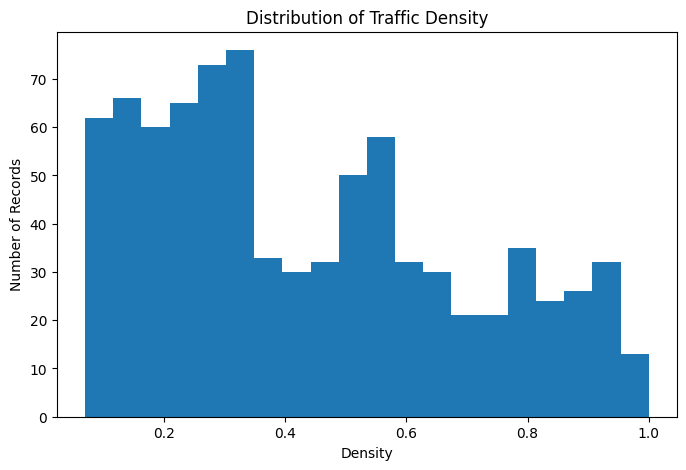

In [21]:
plt.figure(figsize=(8, 5))
plt.hist(traffic["density"].dropna(), bins=20)

plt.xlabel("Density")
plt.ylabel("Number of Records")
plt.title("Distribution of Traffic Density")
plt.show()

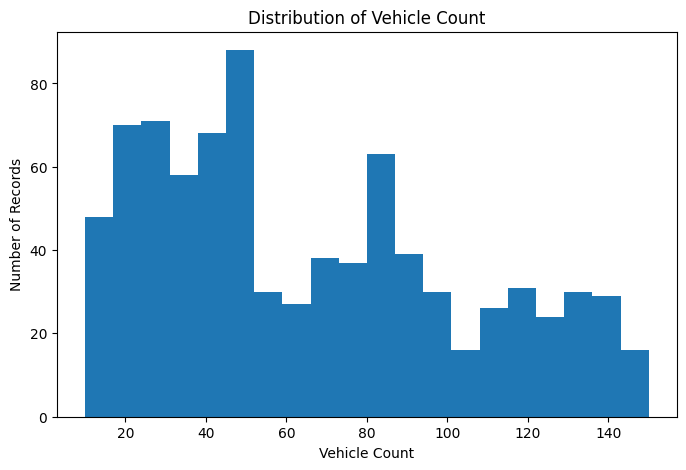

In [22]:
plt.figure(figsize=(8, 5))
plt.hist(traffic["vehicle_count"].dropna(), bins=20)

plt.xlabel("Vehicle Count")
plt.ylabel("Number of Records")
plt.title("Distribution of Vehicle Count")
plt.show()

road_id
R005    0.444107
R002    0.437246
R001    0.435905
R003    0.433631
R004    0.431250
0.25         NaN
43           NaN
Name: density, dtype: float64


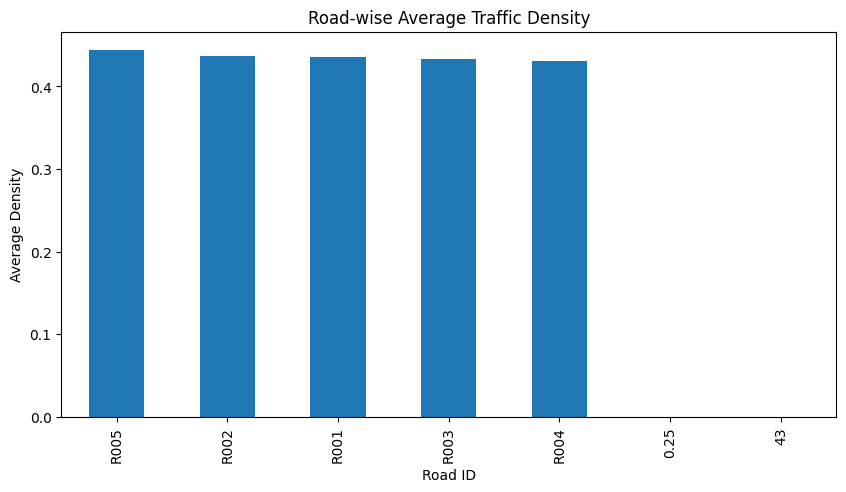

In [23]:
road_summary = (
    traffic.groupby("road_id")["density"]
    .mean()
    .sort_values(ascending=False)
)

print(road_summary)

road_summary.plot(kind="bar", figsize=(10, 5))
plt.xlabel("Road ID")
plt.ylabel("Average Density")
plt.title("Road-wise Average Traffic Density")
plt.show()

hour
0.0     0.200857
1.0     0.199714
2.0     0.202857
3.0     0.218286
4.0     0.203294
5.0     0.182857
6.0     0.191429
7.0     0.719143
8.0     0.715143
9.0     0.657714
10.0    0.716571
11.0    0.440000
12.0    0.416286
13.0    0.434286
14.0    0.428000
15.0    0.432857
16.0    0.414857
17.0    0.778000
18.0    0.783429
19.0    0.776286
20.0    0.743429
21.0    0.204000
22.0    0.212000
23.0    0.196286
Name: density, dtype: float64


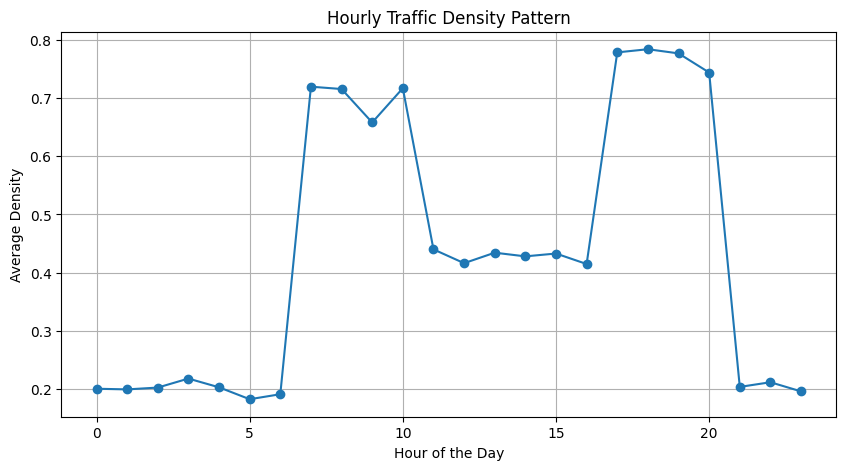

In [24]:
hour_summary = traffic.groupby("hour")["density"].mean()

print(hour_summary)

hour_summary.plot(
    kind="line",
    marker="o",
    figsize=(10, 5)
)

plt.xlabel("Hour of the Day")
plt.ylabel("Average Density")
plt.title("Hourly Traffic Density Pattern")
plt.grid(True)
plt.show()

In [25]:
print("EDA completed successfully.")

print("\nImportant features for congestion prediction:")
print("- Traffic density")
print("- Vehicle count")
print("- Average speed")
print("- Hour of the day")
print("- Road ID")

EDA completed successfully.

Important features for congestion prediction:
- Traffic density
- Vehicle count
- Average speed
- Hour of the day
- Road ID
